# Этап 3. Поисковая инфраструктура и retrieval-пайплайн

In [1]:
DEVICE="mps"
LLM_BASE_URL="http://127.0.0.1:8080/v1"

In [2]:
from sentence_transformers import CrossEncoder, SentenceTransformer

encoder = SentenceTransformer("intfloat/multilingual-e5-base", device=DEVICE)
reranker = CrossEncoder("BAAI/bge-reranker-v2-m3", device=DEVICE)

/Users/a1234/yandex/2/practics/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1112 02:20:43.047000 42982 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 393/393 [00:00<00:00, 8084.25it/s]


In [3]:
import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML
from openai import OpenAI

In [4]:
pd.set_option("display.max_colwidth", 300)
pd.set_option("display.max_rows", None)
def show(*, title: str, df: pd.DataFrame):
    display(HTML(f"""
        <h3 style="
            text-align: center;
            padding-bottom: 8px;
            border-bottom: 1px solid #888;
        ">{title}</h3>
    """))
    display(df)

In [5]:
def metrics(
    got_docs: list[int],
    relevants: list[int],
) -> tuple[float, float, float]:
    """Вычисляет precision, recall и MRR на уровне документов."""

    relevant = set(relevants)
    ranked_docs = list(dict.fromkeys(got_docs))

    if not relevant:
        return float("nan"), float("nan"), float("nan")

    hits = [doc_id for doc_id in ranked_docs if doc_id in relevant]

    precision = len(hits) / len(ranked_docs) if ranked_docs else 0.0
    recall = len(hits) / len(relevant)

    mrr = 1 / (ranked_docs.index(hits[0]) + 1) if hits else 0.0

    return precision, recall, mrr

In [6]:
chunks = pd.read_json("chunks.jsonl", lines=True)
chunk_vecs = np.load("chunk_embeddings.npy")
chunks["chunk_id"] = chunks["chunk_id"].astype(str)
q_df = pd.DataFrame(q for q in json.loads(Path("filmoskop_kb.json").read_text(encoding="utf-8"))["queries"])
q_vecs = encoder.encode(("query: " + q_df["query"]).tolist(), normalize_embeddings=True, batch_size=16)

assert len(q_df) == q_vecs.shape[0]
assert len(chunks) == chunk_vecs.shape[0]

print(f"Чанков: {len(chunks)}")
print(f"Вопросов: {len(q_df)}")

Чанков: 183
Вопросов: 66


## Выбор подхода к построению пайплайна

Для реализации RAG-системы выбран подход с самостоятельной разработкой основных компонентов на Python без использования LangChain.

Такой подход позволяет лучше контролировать каждый этап работы системы: поиск релевантных документов (retrieval), формирование контекста, подготовку промптов, вызов LLM и обработку полученного ответа.

Несмотря на то что LangChain предоставляет готовые абстракции и позволяет быстрее собрать базовый RAG-конвейер, на данном этапе важнее разобраться в принципах работы каждого компонента и сохранить гибкость архитектуры.

Самостоятельная реализация также упрощает отладку, профилирование и последующую замену отдельных компонентов без зависимости от дополнительных абстракций фреймворка.

**Решение:** реализовать собственный RAG-конвейер, используя специализированные библиотеки для отдельных задач, но оставив управление процессом, взаимодействие компонентов и бизнес-логику в собственном коде.

In [7]:
import chromadb

COLLECTION_NAME = "knowledge_base"
client = chromadb.PersistentClient("chroma_db")
try:
    client.delete_collection(COLLECTION_NAME)
except Exception:  # noqa: BLE001, S110
    pass


col = client.create_collection(name=COLLECTION_NAME, configuration={"hnsw": {"space": "cosine", "ef_search": 100}})
col.add(
    ids=chunks["chunk_id"].tolist(),
    embeddings=chunk_vecs.tolist(),
    documents=chunks["chunk_text"].tolist(),
    metadatas=chunks[["chunk_id", "doc_id", "title", "category", "chunk_idx", "token_count"]].to_dict("records")
)

В chroma всегда используется индекс, но на таком объеме данных он фактически равен полному перебору

In [8]:
# Проверка: HNSW на таком корпусе даёт то же, что точный перебор
chroma_top5 = col.query(query_embeddings=q_vecs.tolist(), n_results=5)["ids"]
exact_top5 = chunks["chunk_id"].to_numpy()[np.argsort(-(q_vecs @ chunk_vecs.T), axis=1)[:, :5]]
same = np.sum([set(a) == set(b) for a, b in zip(chroma_top5, exact_top5)])
show(title="Коллекция и проверка точности", df=pd.Series({"чанков в коллекции": col.count(), "запросов, где top-5 совпал с точным поиском": same}).to_frame("value"))

,value
чанков в коллекции,183
"запросов, где top-5 совпал с точным поиском",66


 Вообще для 183 чанка индекс избыточен, но в рамках задания проведём исследование когда он может понадобиться.
 Ответ на этот вопрос зависит не только от количества чанков в бд, но и от максимального допустимого latency(времени на поиск)
 Для примера возьмём максимально допустимую latency 20 мс.<br> Рассчитаем примерно при каком числе чанков мы не будем в него укладываться(расчет не учитывает накладные расходы на поиск в зависимости от хранилища, сетевое оно или в памяти)

In [9]:
def bench_latency(n: int) -> float:
    vecs = np.random.default_rng(42).standard_normal((n, 768), dtype=np.float32)
    q = vecs[0]
    t0 = time.perf_counter()
    for _ in range(10):
        scores = vecs @ q
        np.argpartition(-scores, 19)[:20] # 20 лучших
    return (time.perf_counter() - t0) / 10 * 1000

sizes = [1_000, 10_000, 20_000, 100_000, 200_000, 250_000]
scale = pd.DataFrame({"chunks": sizes, "latency_ms": [bench_latency(n) for n in sizes]})
scale["memory_gb"] = scale["chunks"] * 768 * 4 / 1e9

# Точный поиск считает все векторы по очереди, поэтому время растёт линейно: берём время на один вектор
LIMIT_MS = 20                                                 # допустимая задержка поиска
ms_per_chunk = scale["latency_ms"].iloc[-1] / scale["chunks"].iloc[-1]
n_limit = int(LIMIT_MS / ms_per_chunk)
show(title="Точный поиск: задержка от размера корпуса", df=scale.round(3))
show(title="Граница", df=pd.Series({"чанков при задержке 0,02 с": n_limit, "память под вектора, ГБ": n_limit * 768 * 4 / 1e9}).to_frame("value").round(2))



,chunks,latency_ms,memory_gb
0,1000,0.042,0.003
1,10000,0.689,0.031
2,20000,1.816,0.061
3,100000,9.916,0.307
4,200000,19.550,0.614
5,250000,25.614,0.768


,value
"чанков при задержке 0,02 с",195203.0
"память под вектора, ГБ",0.6


### Вывод по необходимости индекса
Тестовые замеры, подтверждают что скорость поиска растёт линейно в зависимости от размера корпуса векторов. <br> 
Применять и настраивать индекс(сравнивать метрики с эталоном) при допустимом latency 20 мс, потребуется при **~170_000** векторов<br>
Стоит отметить что с ростом числа векторов растёт и потребляемая память для хранения, и это тоже нужно учитывать, применять при необходимости механизмы оптимизации размера(pq, sq)

## Поиск

### Retriver

In [10]:
def retrieve(query: str, k: int = 5, threshold: float = 0.0, category: str | None = None) -> pd.DataFrame:
    """Запрос -> эмбеддинг -> поиск в Chroma -> порог -> top-k чанков с метаданными."""
    q = encoder.encode("query: " + query, normalize_embeddings=True)
    res = col.query(
        query_embeddings=[q.tolist()],
        n_results=k,
        where={"category": category} if category else None,
        include=["documents", "metadatas", "distances"],
    )
    out = pd.DataFrame(res["metadatas"][0])
    out["score"] = 1 - np.array(res["distances"][0])
    out["text"] = res["documents"][0]
    return out[out["score"] >= threshold].reset_index(drop=True)             # отсекаем слабые чанки

#### Фильтрация по метаданным на одном примере

In [11]:
q1 = "сколько устройств могут смотреть одновременно"
show(title="Без фильтра", df=retrieve(q1)[["doc_id", "title", "category", "score"]].round(3))
show(title="Только категория «Подписка и оплата»", df=retrieve(q1, category="Подписка и оплата")[["doc_id", "title", "category", "score"]].round(3))

,doc_id,title,category,score
0,44,Сколько устройств у одного зрителя,Устройства и качество,0.867
1,99,Совместный просмотр,Функции и контент,0.853
2,24,Какой тариф подойдёт именно вам,Подписка и оплата,0.845
3,85,Ошибка P-102: превышен лимит просмотров,Ошибки воспроизведения,0.839
4,166,Привязанные устройства и их лимит,Устройства и качество,0.836


,doc_id,title,category,score
0,24,Какой тариф подойдёт именно вам,Подписка и оплата,0.845
1,113,Тарифы «Фильмоскопа»,Подписка и оплата,0.818
2,168,Первые дни в «Фильмоскопе»,Подписка и оплата,0.804
3,113,Тарифы «Фильмоскопа»,Подписка и оплата,0.798
4,32,Почему зрители выбирают «Максимум»,Подписка и оплата,0.797


In [12]:
# dense retriver on all queries
all_hits = []
all_elapsed = []

# прогрев бд
for q in q_df["query"][:5]:
    retrieve(q)
for q in q_df["query"]:
    t0 = time.perf_counter()
    all_hits.append(retrieve(q, k=20, threshold=-1.0))
    all_elapsed.append((time.perf_counter() - t0) * 1000)


#### Выбор порога релевантности

In [13]:
# вычисляем лучшие скоры для answerable и gap
top1 = pd.Series([h["score"].max() for h in all_hits], index=q_df.index)
answerable_idx, gap_idx = q_df.index[q_df["kind"] != "gap"], q_df.index[q_df["kind"] == "gap"]
top1_ans, top1_gap = top1.iloc[answerable_idx], top1.iloc[gap_idx]
res = pd.DataFrame({"top1 answerable": top1_ans.describe(), "top1 gap": top1_gap.describe()})
show(title="Статистика по топ 1 скору по всем запросам", df=res)

,top1 answerable,top1 gap
count,56.000000,10.000000
mean,0.852880,0.822563
std,0.021556,0.029546
min,0.789579,0.765453
25%,0.839440,0.814917
50%,0.855143,0.820654
75%,0.865228,0.835695
max,0.902197,0.872099


Из распределения видно что скоры gap и answerable пересекаются, p50 gap вопросов выше min answerable, нельзя подобрать порог так чтобы он отсекал все gap и пропускал все answerable<br>
Попробуем подобрать порог с минимальной потерей

In [14]:
candidates = np.sort(pd.concat([top1_ans, top1_gap]).unique())  # все уникальные скоры как кандидаты

rows = []
for t in candidates:
    fr = int((top1_ans < t).sum())   # ложный отказ: ответ есть, а мы отказали
    fa = int((top1_gap >= t).sum())  # ложный приём: ответа нет, а мы ответили (галлюцинация)
    rows.append({"порог": round(t, 3),
                 "ложные_отказы": fr,
                 "ложные_приёмы": fa,
                 "потери_1к1": fr + fa,
                 "потери_1к3": fr + 3 * fa})  # если галлюцинация в 3 раза хуже})

sweep = pd.DataFrame(rows).sort_values("потери_1к3")
show(title="Подбор порога", df=sweep.head(10))

,порог,ложные_отказы,ложные_приёмы,потери_1к1,потери_1к3
12,0.830,5,3,8,14
13,0.834,6,3,9,15
14,0.835,7,3,10,16
11,0.822,5,4,9,17
15,0.835,8,3,11,17
16,0.836,9,3,12,18
17,0.836,10,3,13,19
9,0.821,4,5,9,19
10,0.822,5,5,10,20
18,0.838,11,3,14,20


На данном наборе данных невозможно корректно определить порог. Слишком мало документов и вопросов, нет тестовой выборки. При таких условиях разница между показателяим будет на уровне шума. Но я просто покажу как я бы подошёл к выбору порога.<br>

При подборе порога используется компромисс между двумя типами ошибок:

 - Ложный отказ (False Reject): релевантный контекст присутствует в базе, но его оценка ниже порога, поэтому система отказывается отвечать, хотя необходимая информация доступна.

 - Ложный приём (False Accept): релевантного контекста нет, но оценка найденного чанка достигает порога. В результате нерелевантный контекст передаётся LLM, что повышает риск генерации неподтверждённого ответа.

При низком пороге увеличивается вероятность пропуска нерелевантных чанков в контекст модели. При высоком пороге возрастает количество ложных отказов, поскольку система может отбрасывать и релевантные чанки.

Для нашей системы цена ложного приёма выше цены ложного отказа: генерация ответа на основании нерелевантного контекста потенциально опаснее, чем отказ при наличии информации в базе. Поэтому при оценке порогов используется взвешенная функция потерь:
$$
L = False Reject + 3 × False Accept
$$

Таким образом, ложный приём получает штраф, втрое превышающий штраф за ложный отказ.(значение 3 выбрано для примера, в реальных системах это определяется на стороне бизнеса)

По результатам перебора порогов значение 0.830 обеспечивает приемлемый компромисс между двумя типами ошибок. При этом сохраняется относительно небольшое количество ложных отказов, а число ложных приёмов ограничивается с учётом их повышенной стоимости.

В качестве **начального рабочего значения выбираем порог 0.830**. Его окончательная пригодность должна быть подтверждена на независимой выборке и при оценке качества ответов LLM. Дополнительно необходимо учитывать, что порог retrieval не гарантирует отсутствие галлюцинаций: надёжность системы также зависит от корректного заземления промпта и способности модели отказываться от ответа при недостаточности подтверждающего контекста.


In [15]:
THRESHOLD=0.830

### Функция сбора метрик

,value
recall@5,0.79
precision@5,0.23
mrr,0.64
elapsed_ms,11.16


,recall@5,precision@5,mrr,elapsed_ms
kind,,,,
exact,1.00,0.24,0.84,11.26
multi,0.66,0.30,0.68,11.02
semantic,0.74,0.18,0.49,11.19


,recall
1,0.402
3,0.643
5,0.786
10,0.911
20,0.982


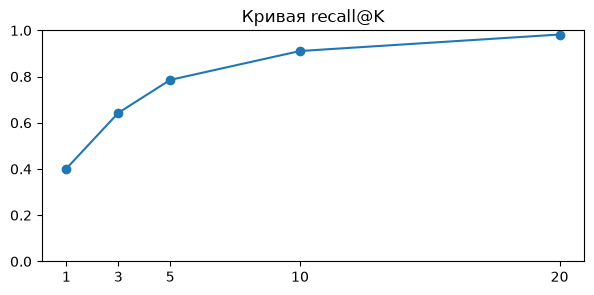

In [16]:
KS = [1, 3, 5, 10, 20]


def evaluate(
    hits_by_query: dict[int, pd.DataFrame], elapsed: list[float]
) -> pd.DataFrame:
    """Расчёт retrieval-метрик для answerable-запросов."""
    rows = []

    for i in answerable_idx:
        hits = hits_by_query[i]
        relevants = q_df.loc[i, "relevant_docs"]

        row = {
            "qi": i,
            "query": q_df.loc[i, "query"],
            "kind": q_df.loc[i, "kind"],
            "elapsed_ms": elapsed[i],
        }

        # Precision@5, Recall@K and MRR.
        for k in KS:
            precision, recall, mrr = metrics(
                got_docs=hits["doc_id"].head(k).tolist(),
                relevants=relevants,
            )
            row[f"recall@{k}"] = recall
            if k == 5:
                row[f"precision@{k}"] = precision
                row["mrr"] = mrr
        rows.append(row)
    return pd.DataFrame(rows)


baseline_hits = {
    i: all_hits[i]
    for i in answerable_idx
}
baseline_metrics = evaluate(baseline_hits, all_elapsed)

def show_retriver_metrics(df: pd.DataFrame, name: str):
    cols = ["recall@5", "precision@5", "mrr", "elapsed_ms"]
    show(title=f"{name} retriver метрики", df=df[cols].mean().round(2).to_frame("value"))
    show(title=f"{name} retriver метрики по типам запросов", df=df.groupby("kind")[cols].mean().round(2))

show_retriver_metrics(baseline_metrics, "baseline")

# Кривая recall@K (без порога)
curve = baseline_metrics[[f"recall@{k}" for k in KS]].mean()
curve.index = KS
show(title="recall@K", df=curve.round(3).to_frame("recall"))
curve.plot(marker="o", xticks=KS, ylim=(0, 1), figsize=(7, 3), title="Кривая recall@K")


metrics_before = baseline_metrics.copy()                   # снимок "до" для сравнения после улучшений
baseline_metrics.to_csv("baseline_per_query.csv", index=False)

## Итоговый вывод по этапу 3

- **Выбор хранилища.** Для проекта выбрана ChromaDB. Она предоставляет удобный Python API, персистентное хранение и встроенную фильтрацию по метаданным. FAISS потребовал бы дополнительной реализации работы с метаданными и хранением, а возможности Qdrant для текущего объёма данных избыточны.

- **Настройка индекса.** Создана коллекция из 221 чанка с использованием HNSW и косинусного расстояния (`space="cosine"`, `ef_search=100`). Состав top-5 результатов совпал с точным поиском на всех 66 проверенных запросах. Отдельный эксперимент показал, что точный поиск укладывается в ограничение 20 мс примерно до 170 тысяч векторов. Для текущего корпуса точного поиска достаточно; пересмотреть решение стоит при приближении к сотням тысяч векторов или превышении допустимой задержки.

- **Retrieval-пайплайн.** Реализована полная последовательность: преобразование запроса в эмбеддинг, поиск ближайших чанков, преобразование расстояния в similarity, фильтрация по порогу и получение top-K результатов вместе с текстом и метаданными.

- **Порог отсечения.** Исследованы распределения максимального сходства для 56 answerable- и 10 gap-запросов. Распределения пересекаются, поэтому разделить эти типы запросов одним порогом без ошибок невозможно. В качестве предварительного значения выбран `threshold = 0.830`, поскольку ложный приём нерелевантного контекста считается более дорогой ошибкой.

- **Фильтрация по метаданным.** Проверена фильтрация по категории «Подписка и оплата». В результатах остаются только чанки указанной категории. Фильтрация выполняется непосредственно средствами ChromaDB.

- **Baseline retrieval.** Оценка проведена на 56 answerable-запросах, без включения gap-запросов. Без порога отсечения получены: `Precision@5 = 0.23`, `Recall@5 = 0.79`, `MRR = 0.65`. Полнота поиска увеличивается с ростом K: от `Recall@1 = 0.402` до `Recall@20 = 0.982`. Применение порога 0.830 повышает Precision@5 до 0.214, но снижает Recall@5 до 0.562 и MRR до 0.441. Поэтому его пока нельзя считать однозначным улучшением поиска.

**Результат этапа:** выбрано и настроено векторное хранилище, реализован retrieval-пайплайн с фильтрацией и порогом отсечения, исследована масштабируемость поиска и зафиксированы baseline-метрики. Эти результаты станут отправной точкой для дальнейших экспериментов по улучшению качества retrieval и генерации ответов.

# Этап 4. Диагностика и улучшение retrieval

In [17]:
# проанализируем проблемные запросы

title_of = chunks.drop_duplicates("doc_id").set_index("doc_id")["title"]   # doc_id -> заголовок раздела


def titles(doc_ids) -> str:
    """Заголовки разделов через точку с запятой."""
    return "; ".join(title_of[d] for d in doc_ids)

def diagnose(df: pd.DataFrame, hits_by_query: dict[int, pd.DataFrame]):
    # Проблемные запросы: нашли не все нужные разделы в top-5
    problems = df[df["recall@5"] < 1].copy()
    problems["нужные разделы"] = [titles(q_df.loc[i, "relevant_docs"]) for i in problems["qi"]]
    problems["в top-5"] = [titles(hits_by_query[i]["doc_id"].head(5).unique()) for i in problems["qi"]]


    # Диагноз по кривой recall@K: нужный раздел в top-20, но ниже пятого места (проблема ранжирования),
    # или его нет даже в top-20 (проблема формулировки, терминов или данных)
    problems["диагноз"] = np.where(problems["recall@20"] == 1, "найден, но ниже top-5", "нет даже в top-20")

    show(title="Проблемные запросы по диагнозу и типу", df=pd.crosstab(problems["диагноз"], problems["kind"], margins=True))
    show(
        title="Проблемные запросы",
        df=problems.sort_values(["диагноз", "recall@5"])[["kind", "query", "recall@5", "recall@20", "диагноз", "нужные разделы", "в top-5"]],
    )
diagnose(baseline_metrics, baseline_hits)

kind,multi,semantic,All
диагноз,,,
"найден, но ниже top-5",10,6,16
нет даже в top-20,0,1,1
All,10,7,17


,kind,query,recall@5,recall@20,диагноз,нужные разделы,в top-5
19,semantic,ребёнок сидит в моём аккаунте — как скрыть от него взрослые фильмы,0.0,1.0,"найден, но ниже top-5",Детский профиль,ПИН-код; Родительский контроль: обзор; Один аккаунт на всю семью; Профили в аккаунте
22,semantic,"начал в метро с телефона, дома хочу досмотреть на большом экране с той же секунды",0.0,1.0,"найден, но ниже top-5",Продолжить просмотр на другом устройстве,Офлайн-просмотр в дороге; Сколько устройств у одного зрителя; Какой тариф подойдёт именно вам; Синхронизация между устройствами; Подключение телевизора к интернету
30,semantic,"боюсь, что ребёнок случайно купит фильм с моей карты",0.0,1.0,"найден, но ниже top-5",ПИН-код,Родительский контроль: обзор; Детский контент и возрастные рейтинги; Аренда и покупка фильмов; Часто задаваемые вопросы об оплате
33,semantic,"хочу убрать из ленты фильмы, которые уже смотрел",0.0,1.0,"найден, но ниже top-5",История просмотров,"Памятка по оценкам; Как выбрать, что посмотреть; Что сервис знает о ваших просмотрах; Оценки «Нравится» и «Не нравится»; Профили в аккаунте"
39,semantic,где менять картинку — в приложении или в самом телевизоре,0.0,1.0,"найден, но ниже top-5",Настройка изображения телевизора для кино,Обновление приложения на телевизоре; Приложения нет в магазине телевизора; Настройки профиля; Известные проблемы текущей версии
53,multi,заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код,0.0,1.0,"найден, но ниже top-5",Аренда и покупка фильмов; ПИН-код,Часто задаваемые вопросы об оплате; Что означают коды ошибок; Прокат и новинки; Как меняются цены; Пробный период
18,semantic,"как сделать, чтобы деньги сами не снимались каждый месяц",0.5,1.0,"найден, но ниже top-5",Автопродление подписки; Отмена подписки и возврат средств,Финансовые вопросы: куда обратиться; Отмена подписки и возврат средств; Как изменить способ оплаты; Годовая подписка; Часто задаваемые вопросы об оплате
40,multi,чем Стандарт отличается от Максимума и потеряю ли оплаченные дни при переходе,0.5,1.0,"найден, но ниже top-5",Тарифы «Фильмоскопа»; Смена тарифа,Смена тарифа; Пробный период; Какой тариф подойдёт именно вам; Отмена подписки и возврат средств
41,multi,сколько устройств могут смотреть одновременно на Стандарте и что будет при превышении,0.5,1.0,"найден, но ниже top-5",Ошибка P-102: превышен лимит просмотров; Тарифы «Фильмоскопа»,Сколько устройств у одного зрителя; Какой тариф подойдёт именно вам; Ошибка P-102: превышен лимит просмотров; Привязанные устройства и их лимит; Совместный просмотр
44,multi,"на новом телевизоре пишет, что достигнут лимит устройств — как отвязать старые и войти",0.5,1.0,"найден, но ниже top-5",Вход на телевизоре по коду; Привязанные устройства и их лимит,Приложение вылетает на телевизоре; Вход на телевизоре по коду; Ошибка P-105: устаревшее приложение; Вход на разных устройствах; Приложения нет в магазине телевизора


По отчёту видно что много проблем связано с тем что релевантные чанки ниже топ-5, применим **подход реранжирования**

In [18]:
def rerank(
    query: str,
    candidates: pd.DataFrame,
    batch_size: int = 16,
) -> pd.DataFrame:
    """Переранжирование кандидатов с помощью Cross-Encoder."""

    if candidates.empty:
        return candidates.copy()

    result = candidates.copy().reset_index(drop=True)

    # Сохраняем идентификатор кандидата и исходную позицию.
    result["candidate_id"] = np.arange(len(result))
    result["dense_rank"] = np.arange(1, len(result) + 1)

    # Формируем пары query-document.
    pairs = [
        (query, text)
        for text in result["text"].fillna("")
    ]

    # Получаем оценки Cross-Encoder.
    scores = reranker.predict(
        pairs,
        batch_size=batch_size,
        show_progress_bar=False,
    )

    result["rerank_score"] = scores

    # Сортируем по убыванию оценки.
    result = result.sort_values(
        "rerank_score",
        ascending=False,
    ).reset_index(drop=True)

    result["rerank_rank"] = np.arange(1, len(result) + 1)

    return result

In [19]:
# Переранжируем кандидатов.
from itertools import islice

reranked_hits = []
reranked_elapsed = []
# прогрев модели
for q, candidates in islice(zip(q_df.loc[answerable_idx, "query"], list(baseline_hits.values())), 10):
    rerank(q, candidates)

for q, candidates in zip(q_df.loc[answerable_idx, "query"], baseline_hits.values()):
    t0 = time.perf_counter()
    reranked_hits.append(rerank(q, candidates))
    reranked_elapsed.append((time.perf_counter() - t0) * 1000)


rerank_metrics = evaluate(reranked_hits, reranked_elapsed)



In [20]:
show_retriver_metrics(name="Метрики после rerank", df=rerank_metrics)

,value
recall@5,0.93
precision@5,0.28
mrr,0.84
elapsed_ms,574.20


,recall@5,precision@5,mrr,elapsed_ms
kind,,,,
exact,1.00,0.24,1.00,561.20
multi,0.84,0.41,0.88,589.19
semantic,0.94,0.22,0.71,572.41


In [21]:
def compare_metrics(
    *,
    before_name: str,
    before_df: pd.DataFrame,
    after_name: str,
    after_df: pd.DataFrame,
    cols: list[str],
):

    # Средние метрики по типам запросов.
    before = before_df.groupby("kind")[cols].mean()
    after = after_df.groupby("kind")[cols].mean()

    # Общие метрики по всем запросам.
    before.loc["overall"] = before_df[cols].mean()
    after.loc["overall"] = after_df[cols].mean()

    # Объединяем результаты.
    compare = pd.concat(
        {
            before_name: before,
            after_name: after,
        },
        axis=1,
    )

    # Считаем абсолютное изменение метрик.
    delta = after - before
    delta.columns = pd.MultiIndex.from_product(
        [["Изменение"], cols]
    )

    compare = pd.concat([compare, delta], axis=1)

    show(
        title="Сравнение метрик: до / после",
        df=compare.round(3),
    )


In [22]:

compare_metrics(before_name="Baseline", before_df=baseline_metrics, after_name="Reranked", after_df=rerank_metrics, cols=["recall@5", "precision@5", "mrr", "elapsed_ms"])

Baseline                               Reranked                     \
         recall@5 precision@5    mrr elapsed_ms recall@5 precision@5    mrr   
kind                                                                          
exact       1.000       0.236  0.839     11.260    1.000       0.237  1.000   
multi       0.656       0.301  0.677     11.024    0.844       0.410  0.875   
semantic    0.740       0.176  0.495     11.186    0.940       0.216  0.715   
overall     0.786       0.228  0.639     11.159    0.929       0.277  0.837   

                    Изменение                                
         elapsed_ms  recall@5 precision@5    mrr elapsed_ms  
kind                                                         
exact       561.205     0.000       0.001  0.161    549.945  
multi       589.186     0.188       0.109  0.198    578.162  
semantic    572.409     0.200       0.040  0.220    561.223  
overall     574.201     0.143       0.049  0.198    563.042

### Итог этапа: диагностика и улучшение качества поиска

- **Диагностика:** по кривой Recall@K и ручному анализу установлено, что основная проблема Dense Retrieval заключается в ранжировании: 16 из 17 проблемных запросов имели все релевантные документы в top-20, но не в top-5. Ещё для 1 запроса часть или все релевантные документы не попали в top-20.
- **Сложности с `multi`:** отдельную проблему представляют составные запросы, содержащие два вопроса одновременно. Для таких запросов сложнее найти документы, релевантные обеим частям запроса: поиск может хорошо обработать одну часть, но пропустить другую. Поэтому качество retrieval для `multi` требует отдельного внимания.
- **Выбор метода:** для решения основной проблемы выбран Cross-Encoder Reranker, использовал модель `BAAI/bge-reranker-v2-m3` который повторно оценивает соответствие запроса найденным кандидатам и меняет порядок выдачи.
- **Результат:** удалось улучшить все основные метрики: Recall@5 вырос с 0.786 до 0.929, Precision@5 с 0.228 до 0.277, MRR с 0.652 до 0.837.
- **Цена улучшения:** время поиска увеличилось примерно с 15 до 600 мс на запрос. Также появилась дополнительная модель и вычислительная нагрузка. При необходимости сократить задержку можно использовать GPU для ускорения инференса Cross-Encoder.
- **Почему не другие методы.** Гибридный поиск с BM25 не нужен: точные термины и коды не были проблемой (exact recall@5 был 1.0. Query expansion и HyDE не брал: 16 из 17 провалов это проблема порядка, а не формулировки, а оба метода добавляют вызов языковой модели на каждый запрос. RRF нужен для слияния нескольких списков кандидатов, а список у нас один. Для запроса с релевантным разделом вне top-20 реранкер не поможет, ему нечего переупорядочивать. Здесь перспективна подход перефраза(query expansion).
**Общий вывод:** основную проблему ранжирования удалось существенно снизить без изменения исходного механизма Dense Retrieval. Полученный прирост качества оправдывает дополнительные вычислительные затраты для сценария, где точность поиска важнее минимальной задержки. При этом составные запросы `multi` остаются отдельной сложностью: для повышения качества поиска по ним можно дополнительно исследовать разбиение запроса на два самостоятельных вопроса с последующим объединением результатов.<br>
---
В результате улучшения поиска удалось поднять **recall@5 до 0.929**.
Целевой показатель задания **recall@5 >= 0,85 по запросам, ответ на которые есть в базе** выполнен.


# Этап 5. Генерация ответов

In [23]:
# Локальный сервер языковой модели (OpenAI-совместимый API)
client = OpenAI(base_url=LLM_BASE_URL, api_key="not-needed")
NO_THINK = {"chat_template_kwargs": {"enable_thinking": False}}   # отключаем режим рассуждений модели
LLM_MODEL = "Qwen-3.5 4B"

POOL, TOP_K = 20, 5                       # кандидатов из векторного поиска -> чанков в промпте после reranker
REFUSAL = "В базе знаний ответа нет."     # единая фраза отказа
REFUSAL_MARK = "в базе знаний ответа нет"  # по ней определяем отказ в ответе

SYSTEM = f"""Ты ассистент поддержки онлайн-кинотеатра «Фильмоскоп». Отвечай только по фрагментам базы знаний из блока <context>.

Правила:
1. Используй только факты из фрагментов. Не добавляй от себя тарифы, цены, сроки, акции и условия.
2. Если во фрагментах нет ответа на вопрос, ответь ровно одной фразой: «{REFUSAL}». Не пытайся угадать.
3. Ответ: 1–3 предложения по-русски, без вступлений. В конце укажи номера использованных фрагментов, например [1][3]."""


def build_messages(query: str, context: pd.DataFrame) -> list[dict]:
    """Промпт: инструкция в system, контекст и вопрос разделены тегами,
    у каждого фрагмента номер и название раздела."""
    fragments = "\n\n".join(
        f"[{i}] (раздел: {row.title})\n{row.text}" for i, row in enumerate(context.itertuples(), 1)
    )
    user = f"<context>\n{fragments}\n</context>\n\n<question>\n{query}\n</question>"
    return [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user}]


def generate(messages: list[dict], max_tokens: int = 300) -> str:
    """Один вызов языковой модели; temperature=0 для воспроизводимости."""
    res = client.chat.completions.create(
        model=LLM_MODEL, messages=messages, temperature=0.0,
        max_tokens=max_tokens, extra_body=NO_THINK,
    )
    return res.choices[0].message.content.strip()


def retrieve_final(query: str, k: int = TOP_K, pool: int = POOL) -> tuple[pd.DataFrame, float]:
    """Итоговый retrieval этапа 4: векторный поиск top-pool -> cross-encoder -> top-k.
    Возвращает чанки и лучшее косинусное сходство (нужно для порога отказа)."""
    candidates = retrieve(query, k=pool, threshold=-1.0)
    return rerank(query, candidates).head(k), float(candidates["score"].max())


def rag_answer(query: str, gold_docs: list[int] | None = None) -> dict:
    """Вопрос -> retrieval -> промпт -> ответ.
    С gold_docs вместо поиска берутся размеченные разделы (для прогона с золотым контекстом на этапе 6)."""
    t0 = time.perf_counter()
    if gold_docs is not None:
        context = (
            chunks[chunks["doc_id"].isin(gold_docs)]
            .sort_values(["doc_id", "chunk_idx"])
            .rename(columns={"chunk_text": "text"})
        )
        dense_top1 = float("nan")
    else:
        context, dense_top1 = retrieve_final(query)
    t1 = time.perf_counter()
    answer = generate(build_messages(query, context))
    t2 = time.perf_counter()
    return {
        "answer": answer,
        "refused_llm": REFUSAL_MARK in answer.lower(),   # модель сама ответила отказом
        "dense_top1": dense_top1,
        "doc_ids": context["doc_id"].tolist(),
        "context": context.copy(),
        "context_text": context["text"].tolist(),
        "retrieval_ms": (t1 - t0) * 1000,
        "llm_ms": (t2 - t1) * 1000,
    }

In [24]:
sample = q_df.groupby("kind").head(2)
test = pd.DataFrame([rag_answer(q) for q in sample["query"]], index=sample.index)
show(
    title="Тестовый прогон: по два запроса каждого типа",
    df=sample[["kind", "query"]].join(test[["answer", "refused_llm", "dense_top1", "retrieval_ms", "llm_ms"]]).round(3),
)

,kind,query,answer,refused_llm,dense_top1,retrieval_ms,llm_ms
0,exact,что означает ошибка P-102,"Ошибка P-102 появляется, когда число одновременных просмотров на аккаунте превышает лимит тарифа. В этом случае просмотр прерывается, и для решения проблемы можно перезапустить приложение, проверить наличие свободного места на устройстве или перейти на тариф с большим числом одновременных просмо...",False,0.862,586.883,2486.954
1,exact,какая версия webOS или Tizen нужна для приложения на телевизоре,"Для работы приложения на телевизорах Samsung (Tizen) требуется версия с 2018 года, а на LG (webOS) — версия 4.0 и новее [1].",False,0.869,632.685,2189.702
15,semantic,"вечером фильмы постоянно тормозят и крутится кружок загрузки, что делать","Вечером сеть часто загружена сильнее всего, поэтому рекомендуется вручную снизить качество в настройках плеера, подключить устройство к роутеру кабелем вместо Wi-Fi и закрыть другие приложения, использующие интернет. Также полезно проверить реальную скорость интернета на вашем устройстве. [1]",False,0.853,647.019,2234.143
16,semantic,"включаю кино — на экране всё идёт, а из колонок тишина","Если изображение воспроизводится, но нет звука, сначала проверьте настройки плеера: откройте меню аудиодорожек и убедитесь, что выбрана нужная дорожка, а громкость не убавлена до нуля [1]. Также проверьте громкость и режим звука на телевизоре или подключённых колонках/наушниках [1].",False,0.848,665.019,2224.981
40,multi,чем Стандарт отличается от Максимума и потеряю ли оплаченные дни при переходе,"Тариф «Стандарт» стоит 399 ₽ в месяц и позволяет смотреть на двух устройствах одновременно с качеством до Full HD, тогда как тариф «Максимум» стоит 599 ₽ в месяц, поддерживает просмотр на четырёх устройствах, качество до 4K HDR со звуком 5.1 и включает все функции сервиса [3]. При переходе на бо...",False,0.840,665.702,3295.991
41,multi,сколько устройств могут смотреть одновременно на Стандарте и что будет при превышении,"На тарифе «Стандарт» разрешено одновременное просмотр на двух устройствах. При превышении этого лимита просмотр на дополнительных устройствах будет невозможен, так как число одновременных просмотров определяется тарифом и не зависит от числа привязанных устройств [1][4].",False,0.847,696.458,2495.630
56,gap,есть ли подарочные сертификаты,В базе знаний ответа нет.,True,0.798,602.047,1159.523
57,gap,есть ли фильмы с аудиоописанием для слабовидящих,В базе знаний ответа нет.,True,0.820,638.734,1193.858


### Итог этапа: реализация RAG и тестирование генерации ответов

- **Что сделал:** объединил Dense Retrieval, Cross-Encoder Reranker и языковую модель Qwen 3.5 4B в единый RAG-пайплайн. Реализовал формирование промпта с системными инструкциями, контекстом из найденных фрагментов и исходным вопросом. Добавил ограничение на использование только базы знаний и единый формат отказа при отсутствии ответа.
- **Что получил:** провел тестовый прогон на 8 запросах: по два запроса каждого типа (`exact`, `semantic`, `multi`, `gap`). В 6 случаях модель сформировала содержательные ответы, в 2 случаях распознала отсутствие достаточной информации и отказалась отвечать.
- **Выявленные проблемы:** составные запросы `multi` остаются более сложными: модель может не полностью обработать вопрос, состоящий из двух частей. В одном из тестов вместо единственной фразы отказа модель добавила пояснение, то есть не полностью соблюла инструкции промпта.
- **Дополнительное наблюдение:** даже у запросов категории `gap` максимальное сходство найденных кандидатов оказалось достаточно высоким (0.820). Следовательно, одного значения Dense Retrieval недостаточно, чтобы надёжно определить, есть ли в базе знаний ответ на вопрос.
- **Принятое решение:** использовать единую RAG-цепочку с Cross-Encoder для отбора контекста и LLM для формирования ответа.
- **Надёжность отказа:** модель не всегда строго соблюдает инструкцию об отказе, поэтому в дальнейшем необходимо отдельно проверить механизм определения достаточности найденного контекста и контроль формата отказа.

**Общий вывод:** реализован рабочий прототип RAG-системы, который объединяет поиск релевантных фрагментов и генерацию ответов на их основе. Тестирование показало, что модель справляется с большинством проверенных запросов, но требует дополнительной проверки соблюдения инструкций, обработки составных вопросов и надёжности механизма отказа.

# Этап 6. Оценка качества и финальная диагностика

### LLM as a JUDGE

In [25]:
JUDGE_FAITH = """
Ты — строгий эксперт по оценке Faithfulness в RAG-системах.

Оцени, насколько утверждения ОТВЕТА подтверждаются КОНТЕКСТОМ.

Шкала:
5 — все утверждения ответа подтверждаются контекстом;
4 — основная информация подтверждается, есть незначительные неподтверждённые детали;
3 — часть утверждений подтверждается, часть не подтверждается;
2 — большинство утверждений не подтверждается контекстом;
1 — ответ содержит выдуманные или противоречащие контексту факты.

Правила:
- Используй только КОНТЕКСТ и ОТВЕТ.
- Не оценивай, насколько ответ отвечает на вопрос.
- Не оценивай правильность ответа относительно внешних знаний.
- Отсутствие утверждения в контексте не доказывает, что оно ложно.
  Оценивай степень подтверждения ответа именно предоставленным контекстом.
- Если ответ полностью состоит из отказа «В базе знаний ответа нет.»,
  поставь 5.

Верни только одну цифру от 1 до 5.
"""


JUDGE_RELEV = """
Ты — строгий эксперт по оценке Answer Relevance.

Оцени, насколько ОТВЕТ отвечает на ВОПРОС по существу.

Шкала:
5 — прямой и полный ответ на вопрос;
4 — ответ по существу, но пропущена незначительная деталь;
3 — ответ частично раскрывает вопрос;
2 — ответ лишь косвенно связан с вопросом;
1 — ответ не отвечает на вопрос или содержит отказ.

Правила:
- Используй только ВОПРОС и ОТВЕТ.
- Не используй контекст и эталонный факт.
- Не оценивай фактическую правильность утверждений.
- Ответ может быть релевантным, даже если он фактически неверен.

Верни только одну цифру от 1 до 5.
"""


JUDGE_CORRECT = """
Ты — строгий эксперт по оценке Correctness.

Сравни ОТВЕТ с ЭТАЛОННЫМ ФАКТОМ (GOLD).

Верни:
1 — ответ передаёт эталонный факт, содержит необходимые сведения
    и не противоречит ему;
0 — ответ противоречит эталону, неполон или отказывается отвечать,
    когда эталон содержит ответ.

Правила:
- Используй только ВОПРОС, ОТВЕТ и GOLD.
- Не используй контекст найденных документов.
- Не используй собственные знания о предметной области.
- Учитывай смысл, а не буквальное совпадение формулировок.
- Если GOLD указывает, что информации в базе знаний нет,
  правильным ответом считается отказ от ответа.

Верни только одну цифру: 1 или 0.
"""


def parse_score(raw: str, allowed: set[int]) -> int:
    """Проверяет и преобразует ответ судьи в числовую оценку."""
    raw = raw.strip()

    if not re.fullmatch(r"\d", raw):
        raise ValueError(f"Некорректный ответ судьи: {raw!r}")

    score = int(raw)

    if score not in allowed:
        raise ValueError(f"Оценка вне допустимого диапазона: {score}")

    return score


def judge(
    question: str,
    context: pd.DataFrame,
    answer: str,
    gold: str,
) -> tuple[int, int, int]:
    """Независимо оценивает faithfulness, answer relevance и correctness."""

    ctx = "\n\n".join(
        f"[{i}] (раздел: {row.title})\n{row.text}"
        for i, row in enumerate(context.itertuples(), 1)
    )

    # Faithfulness: только контекст и ответ.
    faith = generate(
        [
            {"role": "system", "content": JUDGE_FAITH},
            {
                "role": "user",
                "content": f"КОНТЕКСТ:\n{ctx}\n\nОТВЕТ:\n{answer}",
            },
        ],
        max_tokens=8,
    )

    # Answer relevance: только вопрос и ответ.
    relev = generate(
        [
            {"role": "system", "content": JUDGE_RELEV},
            {
                "role": "user",
                "content": f"ВОПРОС:\n{question}\n\nОТВЕТ:\n{answer}",
            },
        ],
        max_tokens=8,
    )

    # Correctness: только вопрос, ответ и эталон.
    correct = generate(
        [
            {"role": "system", "content": JUDGE_CORRECT},
            {
                "role": "user",
                "content": (
                    f"ВОПРОС:\n{question}\n\n"
                    f"ОТВЕТ:\n{answer}\n\n"
                    f"GOLD:\n{gold}"
                ),
            },
        ],
        max_tokens=8,
    )

    return (
        parse_score(faith, {1, 2, 3, 4, 5}),
        parse_score(relev, {1, 2, 3, 4, 5}),
        parse_score(correct, {0, 1}),
    )

In [26]:
rows = []

for q in q_df.itertuples():
    query = q.query
    relevant_docs = q.relevant_docs

    # RAG: retrieval + generation
    rag_res = rag_answer(query)

    # Метрики итоговой выдачи
    precision, recall, mrr = metrics(
        rag_res["doc_ids"],
        relevant_docs
    )

    # Оценка ответа LLM-судьёй
    faith, relev, correct = judge(
        question=query,
        context=rag_res["context"],
        answer=rag_res["answer"],
        gold=q.gold,
    )

    rows.append({
        "kind": q.kind,
        "query": query,
        "gold": q.gold,
        "relevant_docs": relevant_docs,
        "answer": rag_res["answer"],
        "context": rag_res["context"],
        "context_text": rag_res["context_text"],
        "got_docs": rag_res["doc_ids"],

        # Retriever
        "precision@5": precision,
        "recall@5": recall,
        "MRR": mrr,

        # Generator
        "faithfulness": faith,
        "answer relevance": relev,
        "correctness": correct,

        # timings
        "retrieval_ms":rag_res["retrieval_ms"],
        "llm_ms":rag_res["llm_ms"]
    })
report = pd.DataFrame(rows)

In [27]:
report.to_csv("report_judge_rag.csv")

#### Метрики по latency

In [28]:
latency = report.assign(all_ms=report["retrieval_ms"] + report["llm_ms"])[["retrieval_ms", "llm_ms", "all_ms"]]
latency.describe().round(2)

,retrieval_ms,llm_ms,all_ms
count,66.00,66.00,66.00
mean,667.32,2176.37,2843.69
std,34.66,539.03,551.12
min,619.28,733.46,1385.93
25%,645.94,1758.02,2425.02
50%,663.74,2234.08,2906.03
75%,678.36,2564.82,3235.28
max,800.58,3492.91,4168.12


In [29]:
show(title="RAG Latency",df=latency.mean().round(2).to_frame("latency"))

,latency
retrieval_ms,667.32
llm_ms,2176.37
all_ms,2843.69


In [30]:
FULL_RAG_METRICS = [
    "precision@5",
    "recall@5",
    "MRR",
    "faithfulness",
    "answer relevance",
    "correctness",
]
summary = report.groupby("kind")[FULL_RAG_METRICS].mean().round(3)
summary.loc["overall"] = report[FULL_RAG_METRICS].mean().round(3)

show(title="Retriver and Judge Metrics", df=summary)

,precision@5,recall@5,MRR,faithfulness,answer relevance,correctness
kind,,,,,,
exact,0.237,1.000,1.000,5.0,5.000,0.933
gap,NaN,NaN,NaN,5.0,1.800,0.900
multi,0.410,0.844,0.875,5.0,5.000,1.000
semantic,0.216,0.940,0.715,5.0,4.840,0.960
overall,0.277,0.929,0.837,5.0,4.455,0.955


### Ручной просмотр худших запросов

In [31]:
bad = report.loc[report["recall@5"] < 1, ["kind", "query", "gold", "relevant_docs", "got_docs", "context_text", "answer", "recall@5", "correctness"]].head(8)
show(title=f"{len(bad)} ответов с recall@5 < 1", df=bad)
bad_index = bad.index.tolist()
print(bad_index)

,kind,query,gold,relevant_docs,got_docs,context_text,answer,recall@5,correctness
18,semantic,"как сделать, чтобы деньги сами не снимались каждый месяц",отключить автопродление в настройках подписки; доступ сохранится до конца оплаченного периода,"[61, 64]","[155, 180, 35, 176, 64]","[Пробный период\nНачинается всё с обычного оформления: зарегистрируйте аккаунт, выберите тариф и укажите способ оплаты. Карта нужна сразу — она понадобится для будущих списаний, но во время бесплатного доступа деньги с неё не снимаются.\nСервис в это время работает без ограничений: доступен весь...","Чтобы деньги не снимались автоматически, необходимо отменить подписку в настройках до окончания пробного периода или текущего оплаченного срока. Если отмена не произведена вовремя, подписка продлится автоматически по цене выбранного тарифа. [1][5]",0.5,1
37,semantic,"в приложении всё включено, а на телефон ничего не приходит",проверить системные настройки телефона: разрешены ли уведомления приложению и не включён ли режим «Не беспокоить»; после переустановки разрешение выдают заново,[124],"[41, 98, 172, 72, 177]","[Вход с устройства, которым в аккаунте раньше не пользовались, сервис отмечает уведомлением. Такие уведомления относятся к сервисным и не отключаются: они существуют ровно затем, чтобы чужой вход не остался незамеченным.\n\nПриходит обычно два сообщения: письмо на привязанную почту и пуш-уведомл...",В базе знаний ответа нет.,0.0,0
41,multi,сколько устройств могут смотреть одновременно на Стандарте и что будет при превышении,на «Стандарте» два одновременных просмотра; при превышении появляется ошибка P-102,"[85, 113]","[113, 24, 44, 166, 99]","[«Мобильный» — 199 ₽ в месяц. Просмотр на одном устройстве, только телефон или планшет. Качество до 720p. «Стандарт» — 399 ₽ в месяц. Просмотр на двух устройствах одновременно, качество до Full HD (1080p), доступно скачивание на мобильные устройства. «Максимум» — 599 ₽ в месяц. Просмотр на четыр...","На тарифе «Стандарт» разрешено одновременное просмотр на двух устройствах. При превышении этого лимита просмотр на дополнительных устройствах будет невозможен, так как число одновременных просмотров определяется тарифом и не зависит от числа привязанных устройств [1][4].",0.5,1
48,multi,"скачал сериал в дорогу, а место на телефоне кончилось и загрузка сорвалась","ошибка P-109 означает нехватку места; нужно освободить память, при этом на устройстве хранится до 20 загрузок","[144, 178]","[177, 144, 51, 109, 144]","[Скачивание фильмов и сериалов срывается чаще, чем обычный просмотр: загрузка идёт долго, и за это время успевает измениться то, от чего она зависит. Приложение показывает сообщение об ошибке и останавливает скачивание, а начатый файл остаётся в разделе «Загрузки» незавершённым.\n\nПеред большой...","Если место на устройстве закончилось, загрузка может остановиться, и начатый файл останется незавершённым в разделе «Загрузки» [1]. Чтобы продолжить просмотр, удалите повреждённую загрузку из списка и запустите скачивание заново [1].",0.5,1
50,multi,"сменил пароль — нужно ли что-то делать с устройствами, где я уже вошёл","после смены пароля входы сохраняются, поэтому стоит нажать «Выйти на всех устройствах» в разделе «Безопасность»","[9, 55]","[173, 9, 173, 41, 117]","[Что делать при подозрении на взлом\nЧто делать при подозрении на взлом\nЧужой доступ появляется не из-за взлома сервиса, а почти всегда проще: пароль повторяется на другом сайте, откуда он и утёк, либо вход остался на чужом устройстве — у знакомых, в гостинице или на работе.\nПрежде чем действо...","После смены пароля рекомендуется нажать кнопку «Выйти на всех устройствах» в разделе «Безопасность», чтобы разлогинировать все устройства, где выполнен вход. Это действие необходимо выполнить сразу после смены пароля для исключения чужого доступа. [1][2]",0.5,1
53,multi,заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код,"30 дней, чтобы начать, и 48 часов на досмотр после запуска; оплата подтверждается ПИН-кодом, если

[18, 37, 41, 48, 50, 53, 54]


### Ручной разбор запросов с recall@5 < 1

Прочитаны gold-документы, найденные документы, контексты и ответы по всем семи запросам с recall@5 < 1.

| ID | Тип | Recall@5 | Что в контексте и ответе | Диагноз | Correctness(ручная оценка)
|---:|---|---:|---|---| --- |
| 18 | semantic | 0.5 | Найден 64, не найден 61. Ответ верен по сути, но сформулирован как «отменить подписку» вместо «отключить автопродление», нет условия «доступ сохранится до конца оплаченного периода» | Поиск: частичный промах | 0 |
| 37 | semantic | 0.0 | Не найден 124. В топе тематический дистрактор 41 (уведомления о входе с нового устройства). Отказ «в базе ответа нет» корректен относительно контекста | Поиск: полный промах | 0 |
| 41 | multi | 0.5 | Найден 113 (два одновременных просмотра), не найден 85. Ошибка P-102 в ответе отсутствует | Поиск: не покрыта вторая часть вопроса | 0 |
| 48 | multi | 0.5 | Найден 144, не найден 178 (ошибка P-109 означает нехватку места, нужно освободить память). Ответ советует удалить повреждённую загрузку и скачать заново, главное действие отсутствует | Поиск: потеряна ключевая часть ответа | 0 |
| 50 | multi | 0.5 | Найден 9, не найден 55. Рекомендация «Выйти на всех устройствах» присутствует, не объяснено только, что входы после смены пароля сохраняются | Поиск: не полный ответ | 0 |
| 53 | multi | 0.5 | Найден 73, не найден 140 (ПИН-код сервиса). Вместо него в контексте дистрактор 116 (3-D Secure). Ответ объясняет код как требование банка | Поиск: дистрактор вытеснил нужный документ, модель честно пересказала неверный контекст | 0 |
| 54 | multi | 0.5 | Найден 139, не найден 175. «Нужна приставка» верно, Chromecast и AirPlay потеряны | Поиск: не покрыта вторая часть вопроса | 0 |

### Выводы по ручному разбору
При ручном посмотре проблема с multi подтвердилась. Однако судья поставил неполным ответам 1, хотя по факту должен был 0. Это уже проблема судьи, некооректно оценивает. Вероятно это связано с тем что судья и rag запускаются на одной модели. Для судьи нужно выбрать другую более качественную модель, на самом функционале это ни как не отразится. А вот расчёт метрик будет более качественным.
5 multi вопросов некорректы из-за проблемы в поиске.



### Прогон с золотым контекстом:

In [32]:
gold_rows = []

for q in q_df.itertuples():
    golden = rag_answer(
        q.query,
        gold_docs=q.relevant_docs,
    )

    faith, relev, correct = judge(
        question=q.query,
        context=golden["context"],
        answer=golden["answer"],
        gold=q.gold,
    )

    gold_rows.append({
        "kind": q.kind,
        "query": q.query,
        "gold": q.gold,
        "answer": golden["answer"],
        "context_text": golden["context_text"],
        "faithfulness": faith,
        "answer relevance": relev,
        "correctness": correct,
    })
gold_report = pd.DataFrame(gold_rows, index=report.index)
gold_report.to_csv("report_judge_rag_gold.csv")


In [33]:
JUDGE_METRICS = ["faithfulness", "answer relevance", "correctness"]
compare_metrics(before_name="Прогон 66 вопросов", before_df=report, after_name="Прогон 66 запросов на золотом контексте", after_df=gold_report, cols=JUDGE_METRICS)

Прогон 66 вопросов                               \
               faithfulness answer relevance correctness   
kind                                                       
exact                   5.0            5.000       0.933   
gap                     5.0            1.800       0.900   
multi                   5.0            5.000       1.000   
semantic                5.0            4.840       0.960   
overall                 5.0            4.455       0.955   

         Прогон 66 запросов на золотом контексте                               \
                                    faithfulness answer relevance correctness   
kind                                                                            
exact                                        5.0            5.000       0.933   
gap                                          5.0            1.000       1.000   
multi                                        5.0            5.000       0.938   
semantic                                     5.0            5.000       0.960   
overall                                      5.0            4.394       0.955   

            Изменение                               
         faithfulness answer relevance correctness  
kind                                                
exact             0.0            0.000       0.000  
gap               0.0           -0.800       0.100  
multi             0.0            0.000      -0.062  
semantic          0.0            0.160       0.000  
overall           0.0           -0.061       0.000

### Повторно проверим вопросы из ручного разбора

In [34]:
show(title="Bad запросы после золотого прогона", df=gold_report.loc[bad_index, ["kind", "query", "gold", "context_text", "answer", "correctness"]])

,kind,query,gold,context_text,answer,correctness
18,semantic,"как сделать, чтобы деньги сами не снимались каждый месяц",отключить автопродление в настройках подписки; доступ сохранится до конца оплаченного периода,[Подписка продлевается автоматически. Списание происходит за 24 часа до окончания оплаченного периода — так доступ не прерывается. Дату следующего списания можно посмотреть в разделе «Подписка».\n\nАвтопродление можно отключить в настройках подписки — кнопка «Отключить автопродление». Доступ при...,"Чтобы деньги не снимались каждый месяц, вы можете отключить автопродление подписки в настройках подписки. После этого новые списания не будут производиться, и доступ сохранится до конца уже оплаченного периода [1].",1
37,semantic,"в приложении всё включено, а на телефон ничего не приходит",проверить системные настройки телефона: разрешены ли уведомления приложению и не включён ли режим «Не беспокоить»; после переустановки разрешение выдают заново,"[Пуш-уведомления на телефоне можно настроить не только в приложении, но и в системных настройках самого телефона: если уведомления отключены на уровне системы, настройки приложения не помогут.\n\nПроверьте, что приложению разрешены уведомления и что не включён режим «Не беспокоить». После переус...","Если в приложении настройки верны, проверьте системные настройки телефона: убедитесь, что уведомления не отключены на уровне системы и не включен режим «Не беспокоить». После переустановки приложения разрешение на уведомления нужно выдать заново [1].",1
41,multi,сколько устройств могут смотреть одновременно на Стандарте и что будет при превышении,на «Стандарте» два одновременных просмотра; при превышении появляется ошибка P-102,"[Ошибка P-102: превышен лимит просмотров\nОшибка P-102 появляется, когда число одновременных просмотров на аккаунте превышает лимит тарифа. Сообщение показывается в плеере, просмотр при этом прерывается.\nПерезапустите приложение и попробуйте снова. Проверьте, что установлена последняя версия пр...","На тарифе «Стандарт» одновременно могут смотреть два устройства. Если число одновременных просмотров превышает этот лимит, появится ошибка P-102, просмотр прерывается, и для возобновления нужно перезапустить приложение или остановить просмотр на другом устройстве [1][3].",1
48,multi,"скачал сериал в дорогу, а место на телефоне кончилось и загрузка сорвалась","ошибка P-109 означает нехватку места; нужно освободить память, при этом на устройстве хранится до 20 загрузок","[Скачивание фильмов и сериалов\nЗагрузки нужны там, где на связь рассчитывать не приходится: в самолёте, в поезде, в поездке с дорогим мобильным трафиком. Скачанный фильм открывается в приложении и не требует подключения к сети. Никакого отдельного плеера для этого не нужно — фильм играет в том ...","Ошибка P-109 появляется, когда на устройстве не хватает свободного места для загрузки, и просмотр при этом прерывается. Чтобы решить проблему, перезапустите приложение, проверьте наличие свободного места и удалите старые загрузки в разделе «Загрузки», так как они занимают память даже после просм...",1
50,multi,"сменил пароль — нужно ли что-то делать с устройствами, где я уже вошёл","после смены пароля входы сохраняются, поэтому стоит нажать «Выйти на всех устройствах» в разделе «Безопасность»","[Кнопка «Выйти на всех устройствах» находится в настройках аккаунта, раздел «Безопасность».\n\nПосле нажатия все устройства, где выполнен вход, будут разлогинены в течение нескольких минут; на каждом потребуется войти заново. Привязка устройств при этом сохраняется — выход не отвязывает их от ак...","После смены пароля все ранее выполненные входы сохраняются, и вам ничего делать с устройствами не нужно. [2]",0
53,multi,заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код,"30 дней, чтобы начать, и 48 часов на досмотр после запуска; оплата подтверждается ПИН-кодом, если он установлен","[Аренда и покупка фильмов\nПлатные фильмы видны прямо в каталоге: в карточке вместо кнопки «Смотреть» п

### Золотой прогон: повторный разбор семи запросов с (recall@5 < 1 после целевого прогона)

В контекст поданы размеченные gold-документы. Разобраны те же семь запросов.

| ID | Тип | Что в ответе | Результат | Correctness (ручная) |
|---:|---|---|---|---:|
| 18 | semantic | Названо «отключить автопродление в настройках подписки» и условие «доступ сохранится до конца оплаченного периода» | Исправлен | 1 |
| 37 | semantic | Вместо отказа дана проверка системных настроек: разрешения на уведомления, режим «Не беспокоить», повторная выдача разрешения после переустановки | Исправлен | 1 |
| 41 | multi | Названы два одновременных просмотра на «Стандарте» и ошибка P-102 при превышении | Исправлен | 1 |
| 48 | multi | Названа ошибка P-109 (нехватка места) и действие «освободить память, удалить старые загрузки». Вместо совета «удалить битую загрузку» теперь основная причина | Исправлен | 1 |
| 50 | multi | Ответ «вам ничего делать не нужно» противоречит gold, хотя нужный чанк в контексте есть | Не исправлен | 0 |
| 53 | multi | Названы 30 дней на старт, 48 часов на досмотр и код «если он установлен». Дистрактор 3-D Secure ушёл из ответа | Исправлен | 1 |
| 54 | multi | Названа приставка или трансляция с телефона вместо одной приставки | Исправлен | 1 |

### Выводы по ручному разбору

1. **Судья завышал оценки.** Неполным ответам он ставил 1, хотя по бинарной сверке с gold это 0. Скорее всего, судья и RAG работают на одной модели, поэтому судья снисходителен к ответам, похожим на его собственные. Для судьи нужна отдельная, более сильная модель. На работу системы это не влияет, но метрики будут точнее.
2. **Проблема multi подтверждена.** В первом прогоне все 5 multi-запросов из разбора были неполными, потому что поиск не принёс второй документ: потеряны P-102, P-109, ПИН-код, Chromecast/AirPlay и т.д. Модель отвечала честно по тому, что получила.
3. **Золотой прогон это доказывает.** После подачи правильных документов с теми же вопросами и той же моделью исправились 6 из 7 запросов (все 4 из 5 multi и оба semantic). Изменился только контекст, значит, причина в поиске, а не в генерации или промпте.
4. **№50 в расчёт не берём.** Нужный чанк в контексте был, а ответ противоречит gold. Выглядит как единичный сбой генерации. Один запрос выводов по системе не меняет.
5. **Оценка судьи в золотом прогоне не изменилась** (Correctness 95.5%), потому что он и раньше ставил 1 неполным ответам. Реальное улучшение видно только по ручной разметке: 7 плохих ответов (5 multi, 2 semantic) превратились в 1 (multi, №50).

### Проверим gap запросы

In [35]:
gap_answer = report.loc[report["kind"] == "gap", ["kind", "query", "gold", "context_text", "answer"]]
show(title="gap запросы", df=gap_answer)

,kind,query,gold,context_text,answer
56,gap,есть ли подарочные сертификаты,в базе знаний ответа нет; правильное поведение — честный отказ,"[Промокод даёт скидку на подписку или бесплатные дни. Ввести его можно в разделе «Подписка» — поле «У меня есть промокод» — или при оформлении подписки.\n\nПравила простые: один промокод на один аккаунт, скидки по промокодам не суммируются между собой и с другими акциями, у каждого кода есть сро...",В базе знаний ответа нет.
57,gap,есть ли фильмы с аудиоописанием для слабовидящих,в базе знаний ответа нет; правильное поведение — честный отказ,"[У многих фильмов и сериалов есть несколько аудиодорожек: русская озвучка, оригинальная дорожка, иногда — дорожки на других языках.\n\nПереключить дорожку можно прямо в плеере: откройте меню «Аудио» и выберите нужную. Выбор запоминается для конкретного фильма. Набор дорожек зависит от прав на ко...",В базе знаний ответа нет.
58,gap,есть ли скидка для студентов,в базе знаний ответа нет; правильное поведение — честный отказ,"[Сервис регулярно проводит акции: сезонные скидки на подписку, специальные предложения для новых пользователей и совместные акции с партнёрами.\n\nВсе действующие акции публикуются в разделе «Акции» на сайте и в приложении. У каждой акции свои условия и срок действия — читайте их в описании. Ано...",В базе знаний ответа нет.
59,gap,когда выйдет продолжение сериала «Северный экспресс»,в базе знаний даты выхода конкретных сериалов не хранятся; правильное поведение — отказ или отсылка к разделу «Скоро»,"[Раздел «Скоро» на главном экране показывает будущие премьеры сервиса: у каждой карточки указана дата появления в каталоге.\n\nКнопка «Напомнить» в карточке будущей премьеры включает уведомление — оно придёт в день выхода. Для сериалов, которые выходят посерийно, той же кнопкой включается уведом...",В базе знаний ответа нет.
60,gap,можно ли смотреть эфирные телеканалы,в базе знаний ответа нет; правильное поведение — честный отказ,"[Стабильность просмотра сильно зависит от того, как телевизор подключён к сети.\n\nСамый надёжный вариант — кабель: подключите телевизор или приставку к роутеру напрямую через порт LAN. Если тянуть кабель неудобно, используйте Wi-Fi на частоте 5 ГГц: она быстрее и меньше загружена, чем 2,4 ГГц. ...",В базе знаний ответа нет.
61,gap,есть ли программа лояльности с баллами за просмотры,в базе знаний ответа нет; правильное поведение — честный отказ,"[Промокоды и акционные предложения действуют поверх выбранного тарифа: скидка применяется к очередному списанию, а когда акция заканчивается, подписка продлевается по обычной цене тарифа. Проверить, применён ли промокод, можно там же, в настройках подписки.\nТариф действует на весь аккаунт, а не...",В базе знаний ответа нет.
62,gap,можно ли оплатить подписку криптовалютой,в базе знаний ответа нет; правильное поведение — честный отказ,"[Способы оплаты\nСпособы оплаты Оплатить подписку можно любым из способов: банковской картой МИР, Visa или Mastercard, выпущенной в России; через Систему быстрых платежей (СБП); со счёта мобильного телефона — только для тарифа «Мобильный». Карта привязывается к аккаунту при первой оплате. Сменит...",В базе знаний ответа нет.
63,gap,"можно ли скачать фильм на телевизор, чтобы посмотреть без интернета","в базе знаний прямого ответа нет; скачивание описано только для телефонов и планшетов, поэтому корректен отказ или ссылка на это ограничение","[Скачивание фильмов и сериалов\nЗагрузки нужны там, где на связь рассчитывать не приходится: в самолёте, в поезде, в поездке с дорогим мобильным трафиком. Скачанный фильм открывается в приложении и не требует подключения к сети. Никакого отдельного плеера для этого не нужно — фильм играет в том ...",Скачивание фильмов для просмотра без интернета на телевизорах не работает. Доступна только функция офлайн-просмотра на телефонах и планшетах. [1]
64,gap,можно ли выгрузить историю просмотров файлом,в базе знаний ответа нет; правильное поведение — честный отказ,[История просмотров хранится отдельно для каждо

Все gap запросы корректны (9 из 10 честный отказ). 1 вопрос № 65 тоже следует считать корректным, потому что в контексте есть нужная информация, модель ответила правильно, возможно тут проблема с типом запроса в разметке

## Матрица диагнозов
## Диагностика по матрице диагнозов

| Тип | Precision@5 | Recall@5 | MRR | Faithfulness | Answer relevance | Correctness | Диагноз |
|---|---:|---:|---:|---:|---:|---:|---|
| exact | 0.237 | 1.000 | 1.000 | 5.0 | 5.000 | 0.933 | Проблемы нет. Нужный документ всегда находится и стоит первым. Низкий precision объясняется потолком: gold-документ один, K=5, больше 0.2 получить нельзя |
| semantic | 0.216 | 0.940 | 0.715 | 5.0 | 4.840 | 0.960 | Умеренная проблема поиска. Recall высокий, но MRR 0.715: нужный документ часто не на первых позициях, единичные запросы вообще не находятся. Профиль «низкий recall + высокая faithfulness» выражен слабо. Участок: поиск (ранжирование, переформулировка запроса) |
| multi | 0.410 | 0.844 | 0.875 | 5.0 | 5.000 | 1.000 | Проблема поиска. Самый низкий recall среди категорий при faithfulness 5.0: поиск не доносит один из нужных документов, модель честно отвечает по найденному. Correctness 1.000 при recall 0.844 не сходятся, это завышение судьи (см. ручной разбор ниже) |
| gap | — | — | — | 5.0 | 1.800 | 0.900 | Проблемы пайплайна нет. Профиль «высокие faithfulness и correctness + низкая answer relevance» здесь ожидаем: ответа в базе нет, корректный отказ не отвечает на вопрос и получает relevance 1. Это артефакт метрики, а не дефект. Precision/recall не считаются, gold-документов нет. Correctness 0.9 (1 из 10) — ошибка разметки №65, а не поиска или генерации |
| overall | 0.277 | 0.929 | 0.837 | 5.0 | 4.455 | 0.955 | Проблемный участок — поиск |

**Вывод: проблемный участок пайплайна — поиск (retrieval), прежде всего multi-запросы, во вторую очередь semantic.** Генерация и данные не причина.

Остальные диагнозы матрицы не подтверждаются:

- **Высокий recall + низкая faithfulness:** faithfulness = 5.0 везде, модель не дописывает своё.
- **Низкий precision при высоком recall:** precision упирается в потолок (1–2 gold-документа при K=5), контекст не раздут.
- **Высокие recall и faithfulness + низкая correctness:** чанки целые, битых или обрезанных не выявлено.
- **Низкий recall + низкая faithfulness:** выдумывания нет, модель отвечает по контексту либо отказывает.

Ограничение: faithfulness = 5.0 во всех категориях, поэтому как сигнал она слабая, а correctness у судьи завышена (см. ручной разбор). Основной аргумент в пользу поиска — recall@5 по multi, подтверждённый разбором и золотым прогоном.

# Итоговый вердикт этапа

### 1. Достигнуты ли целевые ориентиры

| Ориентир | Цель | Результат | Статус |
|---|---|---|---|
| Recall@5 по запросам с ответом в базе | ≥ 0.85 | [0.929] | **[достигнут]** |
| Correctness по всему набору | ≥ 0.90 | По судье 95.5% (63/66). С ручной оценкой семи запросов: (63 − 7)/66 = 84.8%, где 7 число запросов которые судья не верно оценил в 1 | **[не достигнут]** |
| Отказ на вопросах без ответа в базе | Согласованная фраза отказа, факты не выдумываются | 9 из 10 (1 спорный), Faithfulness = 5.0 | **[достигнут]** |

Оценка судьи завышена: неполным ответам он ставил 1 вместо 0, поэтому ориентир по correctness снижается по ручной разметке.
Faithfulness = 5 у всех категорий. Это ограничение судьи (проверяет только опору на контекст), а не сигнал о качестве.

### 2. Готова ли система к пилоту

**[Не готова - достигнуты только 2 из 3 целевых ориентира]**

Диагноз по multi подтверждён двумя независимыми проверками:

- Ручной разбор: во всех пяти multi-запросах с recall@5 < 1 потерян один из gold-документов, а ответ полный только по первой части вопроса.
- Золотой прогон: при подаче размеченных документов из семи плохих запросов (5 multi, 2 semantic) осталось 1 (№50, единичный сбой генерации). Меняется только контекст, поэтому причина в поиске, а не в модели и не в промпте.

### 3. Три рекомендации

**1. Починить поиск: multi в первую очередь, затем semantic.**

- Multi: декомпозиция запроса на подзапросы, независимый поиск по каждому, слияние кандидатов через RRF с дедупликацией по чанку, реранкинг по исходному запросу, одна генерация по объединённому контексту. Объединять контексты, а не готовые ответы.
- Semantic: query rewriting или HyDE, гибридный поиск

*Зачем:* золотой прогон показал, что при наличии нужных документов система отвечает верно в 6 из 7 случаев, а реранкер не восстановит документ, которого поиск не принёс.

**2. Усилить оценку качества.**

- Заменить модель-судью на отдельную, более сильную. Откалибровать на ручной разметке (agreement на этих семи запросах).
- Считать correctness по чек-листу фактов gold: полнота (доля переданных фактов) и наличие неверных утверждений.
- Для gap-запросов оценивать корректность отказа отдельно от answer relevance: правильный отказ сейчас получает низкую relevance.

**3. Расширить и исправить тестовый набор.**

- Больше запросов в multi и semantic, сопоставимое покрытие категорий.
- Исправить разметку №65 (отнесён к gap, хотя ответ в базе есть).
- Зафиксировать семь разобранных запросов как регрессионный набор, замерять recall@5 и correctness до и после каждой доработки.
- На 66 запросах разница в один-два запроса неотличима от шума, поэтому набор нужно расширять.

# Общий вывод

Реализована RAG-система полного цикла: индексация, dense-поиск, реранкинг, генерация. Recall@5 выявил проблему с multi-запросами, ручной разбор семи запросов с recall@5 < 1 подтвердил, что ответы там неполные (потеряна вторая часть вопроса), а судья это пропустил из-за снисходительной оценки. Золотой прогон показал, что с правильным контекстом 6 из 7 плохих ответов становятся верными, значит, проблема в поиске, а не в генерации. Основное направление доработки: декомпозиция multi-запросов с RRF, переформулировка и гибридный поиск для semantic, замена судьи.